# Hexbin Plot

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Bins a large scatter into hexagonal cells colored by point count. It replaces an unreadable blob of overplotted points with a readable density surface.

## When to use

- Show a two-variable relationship with thousands to millions of points
- Show where the data is concentrated, not just its extent

## Avoid when

- There are only a few hundred points (a scatter shows individual points better)
- Individual outliers matter (binning hides them)

## Alternatives

- 2-D density contour
- Scatter with transparency

## Design tips

- Use a single-hue sequential color map, light = few, dark = many
- Try a log color scale when density is very skewed

## Example

50,000 taxi trips: trip distance vs. fare (synthetic data).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(0)
n = 50_000
distance = rng.gamma(2.0, 1.6, n)
fare = 3 + 2.4 * distance + rng.normal(0, 1.2 + 0.25 * distance, n)
df = pd.DataFrame({"distance_km": distance, "fare_usd": fare}).query("fare_usd > 2")
df.describe().round(1)

,distance_km,fare_usd
count,49702.0,49702.0
mean,3.2,10.7
std,2.3,5.8
min,0.0,2.0
25%,1.6,6.6
50%,2.7,9.5
75%,4.3,13.6
max,23.7,67.8


### Plot

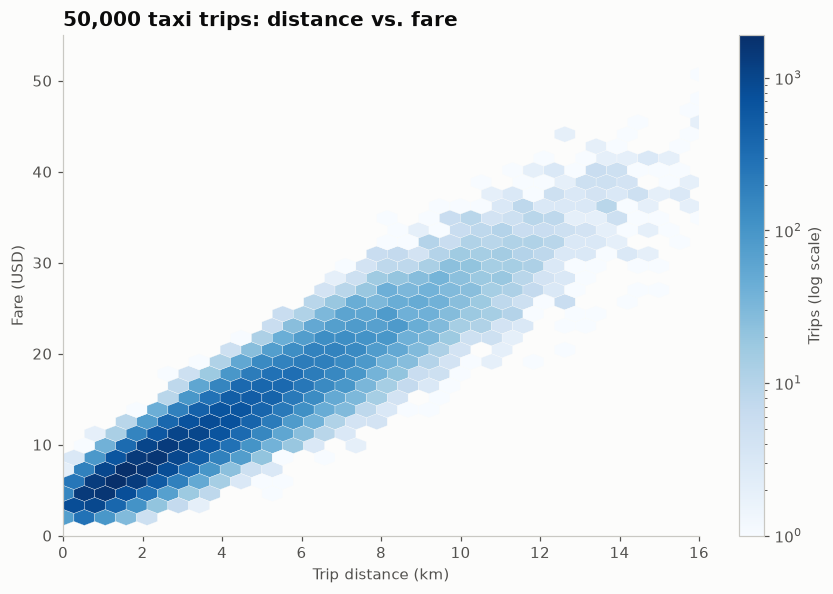

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
hb = ax.hexbin(df["distance_km"], df["fare_usd"], gridsize=45, cmap=SEQ_CMAP,
               bins="log", mincnt=1, linewidths=0.2, edgecolors="#fcfcfb")
ax.set_xlim(0, 16); ax.set_ylim(0, 55)
ax.grid(False)
fig.colorbar(hb, ax=ax, label="Trips (log scale)")
ax.set_xlabel("Trip distance (km)")
ax.set_ylabel("Fare (USD)")
ax.set_title("50,000 taxi trips: distance vs. fare")
fig.tight_layout()
plt.show()

## How to read it

Darker hexagons hold more trips. Most trips are short and cheap (bottom left). The fan shape shows fares vary more on longer trips.

---
Standalone script: [`hexbin.py`](hexbin.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)